In [2]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os

In [3]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

In [4]:
path = tf.keras.utils.get_file(
    "flower_photos",
    origin=url,
    untar=True
)
path = os.path.join(path, "flower_photos")
print(path)
print(os.listdir(path))

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
/root/.keras/datasets/flower_photos/flower_photos
['tulips', 'daisy', 'roses', 'dandelion', 'sunflowers', 'LICENSE.txt']


In [5]:
# Training Dataset
img_size = (128, 128)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="training",
    seed=42
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [6]:
# Validate the data
val_ds = tf.keras.utils.image_dataset_from_directory(
    path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.2,
    subset="validation",
    seed=42
)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


In [7]:
class_names = train_ds.class_names

print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [8]:
# Build CNN Model

model = models.Sequential([
layers.Input(shape=(128,128,3)),
layers.Rescaling(1./255),     #normalized
layers.Conv2D(32,(3,3),activation="relu"),
layers.MaxPooling2D((2,2)),
layers.Conv2D(64,(3,3),activation="relu"),
layers.MaxPooling2D((2,2)),
layers.Conv2D(128,(3,3),activation="relu"),
layers.MaxPooling2D((2,2)),
layers.Flatten(),
layers.Dropout(0.5),
layers.Dense(128,activation="relu"),
layers.Dense(5,activation="softmax")
])

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Complie CNN Model

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
# Train CNN Model

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8
)

Epoch 1/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 62s 667ms/step - accuracy: 0.4142 - loss: 1.3463 - val_accuracy: 0.5572 - val_loss: 1.0702
Epoch 2/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 61s 663ms/step - accuracy: 0.5906 - loss: 1.0252 - val_accuracy: 0.6131 - val_loss: 1.0131
Epoch 3/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 62s 670ms/step - accuracy: 0.6509 - loss: 0.8953 - val_accuracy: 0.6390 - val_loss: 0.9313
Epoch 4/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 87s 725ms/step - accuracy: 0.7016 - loss: 0.7832 - val_accuracy: 0.6567 - val_loss: 0.9732
Epoch 5/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 60s 656ms/step - accuracy: 0.7551 - loss: 0.6608 - val_accuracy: 0.6907 - val_loss: 0.9167
Epoch 6/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 90s 749ms/step - accuracy: 0.8007 - loss: 0.5428 - val_accuracy: 0.6948 - val_loss: 0.8692
Epoch 7/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 78s 710ms/step - accuracy: 0.8375 - loss: 0.4309 - val_accuracy: 0.6935 - val_loss: 1.0072
Epoch 8/8
92/92 ━━━━━━━━━━━━━━━━━━━━ 61s 658ms/step - accuracy: 0.8730 - loss: 0.3430 - val_accuracy: 0.

In [15]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
from PIL import ImageFile

# Allow PIL to load truncated/damaged images
ImageFile.LOAD_TRUNCATED_IMAGES = True

img = load_img(
    "white-daisy-flower.jpg",
    target_size=(128, 128)
)

img_array = img_to_array(img)
img_array = np.expand_dims(
    img_array,
    axis=0
)

In [16]:
# Prediction
prediction = model.predict(img_array)
predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

print("Predicted Flower:", predicted_class)
print("Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Predicted Flower: daisy
Confidence: 99.68414


In [17]:
val_loss, val_accuracy = model.evaluate(val_ds)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 217ms/step - accuracy: 0.6948 - loss: 1.1123
Validation Loss: 1.1123125553131104
Validation Accuracy: 0.6948229074478149


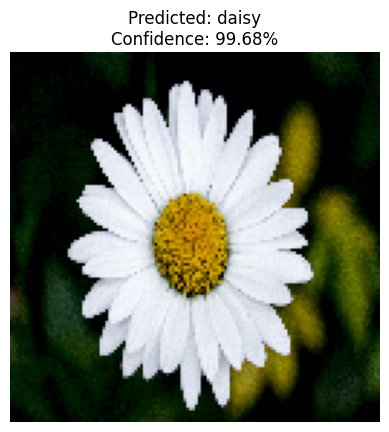

In [18]:
import matplotlib.pyplot as plt

plt.imshow(img)
plt.title(
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

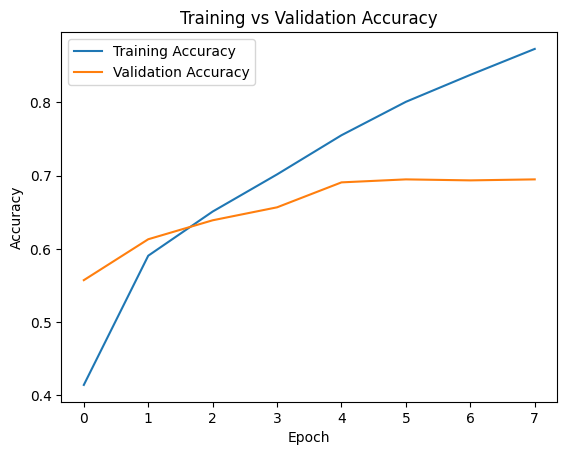

In [19]:

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

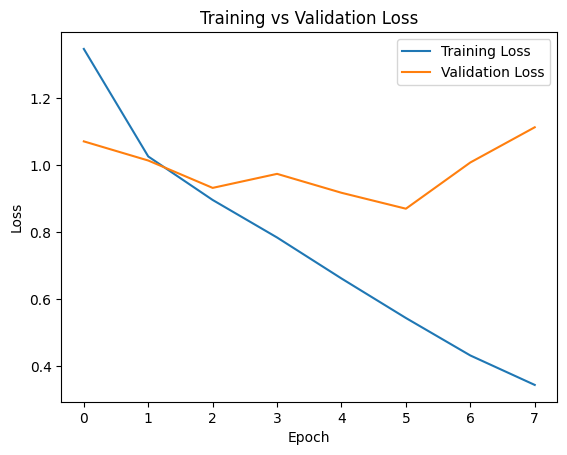

In [21]:
# Analysing the model- Training Vs Validation Curves
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()